# Phase 2: Baseline Models & Uncalibrated Evaluation

## Goals
- Train XGBoost, LightGBM, and MLP baseline models
- Evaluate classification performance (AUROC, AUPRC, F1)
- **Crucially**: Evaluate calibration (ECE, Brier score, reliability diagrams)
- Compare i.i.d. vs temporal-split calibration
- Establish the miscalibration problem before applying fixes

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils.helpers import load_config, set_seed
from src.data.loader import get_dataset, load_creditcard, preprocess_creditcard
from src.data.splits import temporal_split_creditcard
from src.models.baselines import get_model
from src.evaluation.calibration_metrics import (
    compute_all_calibration_metrics, reliability_diagram_data
)
from src.evaluation.visualization import plot_reliability_diagram

config = load_config('../configs/config.yaml')
set_seed(config['experiment']['seed'])
print('Setup complete.')

Setup complete.


In [2]:
# Load and split data (split FIRST, then preprocess with train-only statistics
# to avoid temporal leakage)
df_raw = load_creditcard(f"../{config['data']['creditcard_path']}")
splits = temporal_split_creditcard(df_raw)
X, y = preprocess_creditcard(df_raw, train_idx=splits['train'])

X_train, y_train = X.iloc[splits['train']].values, y[splits['train']]
X_cal, y_cal = X.iloc[splits['calibration']].values, y[splits['calibration']]
X_val, y_val = X.iloc[splits['val']].values, y[splits['val']]
X_test, y_test = X.iloc[splits['test']].values, y[splits['test']]

print(f'Train: {len(y_train)} (fraud: {y_train.sum()})')
print(f'Cal:   {len(y_cal)} (fraud: {y_cal.sum()})')
print(f'Val:   {len(y_val)} (fraud: {y_val.sum()})')
print(f'Test:  {len(y_test)} (fraud: {y_test.sum()})')

Train: 170884 (fraud: 360)
Cal:   42721 (fraud: 38)
Val:   28480 (fraud: 42)
Test:  42722 (fraud: 52)


## Train Baseline Models

In [3]:
models = {}
predictions = {}
results = {}

for model_name in ['xgboost', 'lightgbm']:
    print(f'\n{"="*50}')
    print(f'Training: {model_name}')
    print(f'{"="*50}')
    
    model_config = config['models'].get(model_name, {})
    model = get_model(model_name, model_config)
    model.fit(X_train, y_train, X_val, y_val)
    
    models[model_name] = model
    probs = model.predict_proba(X_test)
    predictions[model_name] = probs
    
    clf_metrics = model.evaluate(X_test, y_test)
    cal_metrics = compute_all_calibration_metrics(probs, y_test)
    results[model_name] = {**clf_metrics, **cal_metrics}
    
    print(f'AUROC: {clf_metrics["auroc"]:.4f}')
    print(f'AUPRC: {clf_metrics["auprc"]:.4f}')
    print(f'ECE:   {cal_metrics["ece"]:.4f}')
    print(f'Brier: {cal_metrics["brier_score"]:.6f}')


Training: xgboost
[0]	validation_0-aucpr:0.67333	validation_1-aucpr:0.51974


c:\Users\debas\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:57:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[100]	validation_0-aucpr:0.98297	validation_1-aucpr:0.75288
[200]	validation_0-aucpr:1.00000	validation_1-aucpr:0.79833
[300]	validation_0-aucpr:1.00000	validation_1-aucpr:0.81122
[400]	validation_0-aucpr:1.00000	validation_1-aucpr:0.81763
[499]	validation_0-aucpr:1.00000	validation_1-aucpr:0.82254
AUROC: 0.9783
AUPRC: 0.7546
ECE:   0.0005
Brier: 0.000476

Training: lightgbm


c:\Users\debas\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 360, number of negative: 170524
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.016743 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 170884, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.002107 -> initscore=-6.160527
[LightGBM] [Info] Start training from score -6.160527
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

## Reliability Diagrams (Uncalibrated)

These diagrams are the key visualization. If models are well-calibrated, bars should align with the diagonal. Deviation = miscalibration.

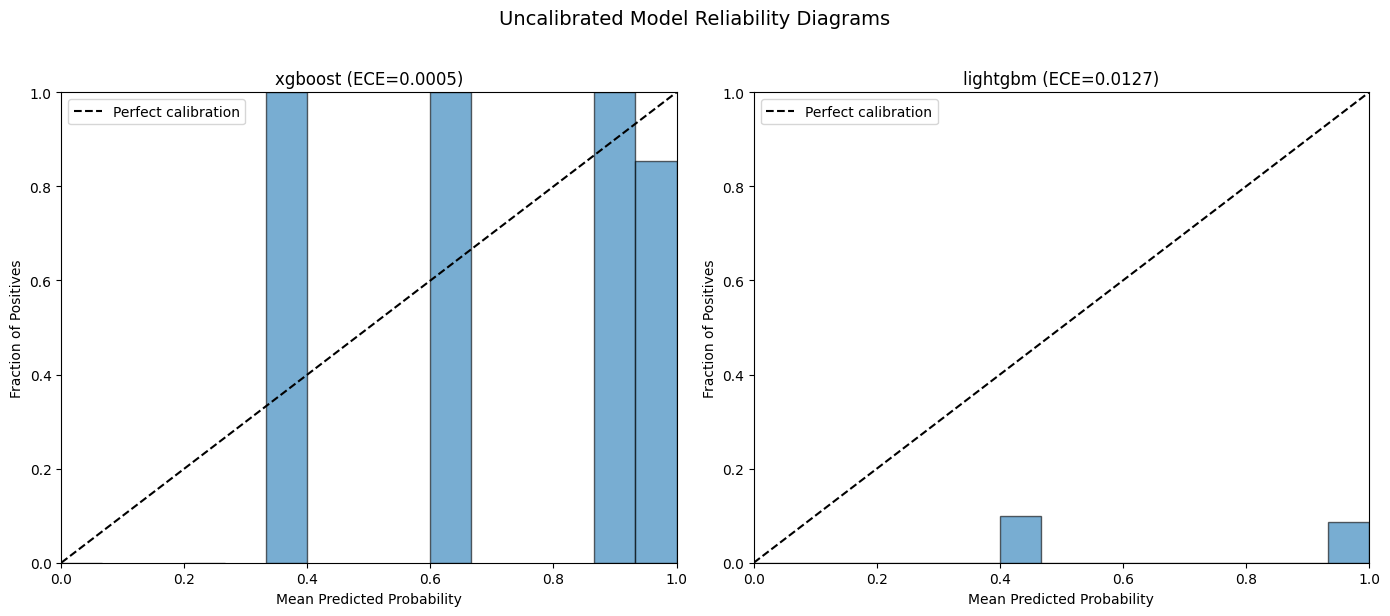

In [4]:
n_models = len(predictions)
fig, axes = plt.subplots(1, n_models, figsize=(7*n_models, 6))
if n_models == 1:
    axes = [axes]

for ax, (name, probs) in zip(axes, predictions.items()):
    plot_reliability_diagram(
        probs, y_test, n_bins=15,
        title=f'{name} (ECE={results[name]["ece"]:.4f})',
        ax=ax
    )

plt.suptitle('Uncalibrated Model Reliability Diagrams', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../results/figures/uncalibrated_reliability.png', dpi=150, bbox_inches='tight')
plt.show()

## Results Summary Table

In [5]:
results_df = pd.DataFrame(results).T
results_df.index.name = 'Model'
print(results_df.to_markdown())
results_df.to_csv('../results/tables/baseline_results.csv')
results_df

| Model    |    auroc |     auprc |         ece |      mce |   brier_score |        nll |
|:---------|---------:|----------:|------------:|---------:|--------------:|-----------:|
| xgboost  | 0.978346 | 0.754619  | 0.000469548 | 0.651229 |   0.000476215 | 0.00373476 |
| lightgbm | 0.830158 | 0.0915513 | 0.0126515   | 0.910746 |   0.0120886   | 0.200326   |


,auroc,auprc,ece,mce,brier_score,nll
Model,,,,,,
xgboost,0.978346,0.754619,0.000470,0.651229,0.000476,0.003735
lightgbm,0.830158,0.091551,0.012651,0.910746,0.012089,0.200326


## Key Findings

Document observations:
1. Are models overconfident or underconfident?
2. Which model has worst/best calibration?
3. How does ECE compare to AUROC — is a model with higher AUROC also better calibrated?
4. What does the reliability diagram shape tell us about the miscalibration pattern?